Criando as visualizações de dados e para isso importando as bibliotecas de vizualização do python

In [3]:
#graficos e bibliotecas
# (instale as dependências com: pip install -r requirements/requirements.txt)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
# Pasta onde está a base tratada, relativa à pasta notebooks/
# (o arquivo é gerado por `python src/main.py`)
from pathlib import Path

PASTA_PROCESSED = Path('..') / 'data' / 'processed'

In [5]:
# Carrega a base salva (formato Parquet)
df_2 = pd.read_parquet(PASTA_PROCESSED / 'dados_anp_tratados.parquet')

In [6]:
# Confere se o DataFrame carregou certo
print(df_2.shape)
df_2.head()

(4322192, 9)


,data_coleta,regiao,estado,municipio,bandeira,produto,valor_venda,ano,mes
0,2021-01-01,S,RS,SAO LEOPOLDO,BRANCA,GASOLINA,4.599,2021,1
1,2021-01-01,S,RS,SAO LEOPOLDO,BRANCA,ETANOL,4.199,2021,1
2,2021-01-01,S,RS,SAO LEOPOLDO,BRANCA,GASOLINA ADITIVADA,4.799,2021,1
3,2021-01-01,S,RS,SAO LEOPOLDO,BRANCA,DIESEL,3.499,2021,1
4,2021-01-01,S,RS,SAO LEOPOLDO,BRANCA,DIESEL S10,3.599,2021,1


In [7]:
df_anp = df_2[['data_coleta', 'regiao', 'estado', 'municipio', 'bandeira','produto', 'valor_venda']]

In [8]:
df_anp.head()

,data_coleta,regiao,estado,municipio,bandeira,produto,valor_venda
0,2021-01-01,S,RS,SAO LEOPOLDO,BRANCA,GASOLINA,4.599
1,2021-01-01,S,RS,SAO LEOPOLDO,BRANCA,ETANOL,4.199
2,2021-01-01,S,RS,SAO LEOPOLDO,BRANCA,GASOLINA ADITIVADA,4.799
3,2021-01-01,S,RS,SAO LEOPOLDO,BRANCA,DIESEL,3.499
4,2021-01-01,S,RS,SAO LEOPOLDO,BRANCA,DIESEL S10,3.599


In [9]:
df_anp['ano'] = df_anp['data_coleta'].dt.year
df_anp['mes'] = df_anp['data_coleta'].dt.month

In [10]:
df_anp.head()

,data_coleta,regiao,estado,municipio,bandeira,produto,valor_venda,ano,mes
0,2021-01-01,S,RS,SAO LEOPOLDO,BRANCA,GASOLINA,4.599,2021,1
1,2021-01-01,S,RS,SAO LEOPOLDO,BRANCA,ETANOL,4.199,2021,1
2,2021-01-01,S,RS,SAO LEOPOLDO,BRANCA,GASOLINA ADITIVADA,4.799,2021,1
3,2021-01-01,S,RS,SAO LEOPOLDO,BRANCA,DIESEL,3.499,2021,1
4,2021-01-01,S,RS,SAO LEOPOLDO,BRANCA,DIESEL S10,3.599,2021,1


In [11]:
df_anp['produto'].unique()

<StringArray>
['GASOLINA', 'ETANOL', 'GASOLINA ADITIVADA', 'DIESEL', 'DIESEL S10', 'GNV']
Length: 6, dtype: str

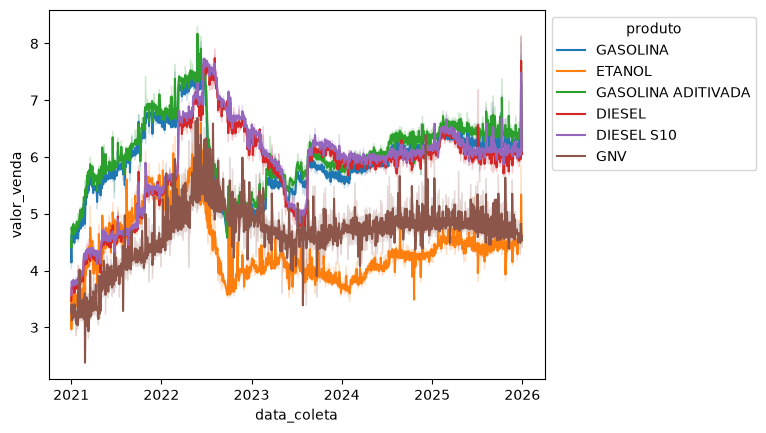

In [12]:
ax = sns.lineplot(data = df_anp, x="data_coleta", y ='valor_venda',   hue="produto")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

Criando funções que auxiliam a plotar outros gráficos

In [14]:
def plotar_boxplot_2V(titulo, labelx, labely, x, y, dataset):
    sns.set_palette('Accent')
    sns.set_style('darkgrid')
    ax = sns.boxplot(x=x, y= y, data=dataset)
    ax.figure.set_size_inches(12,6)
    ax.set_title(titulo, loc = 'left', fontsize = 18)
    ax.set_xlabel(labelx, fontsize = 14)
    ax.set_ylabel(labely, fontsize = 14);

In [15]:
def plotar_boxplot_geral(y, dataset):
    ax = sns.boxplot(y=y, data=dataset)
    ax.figure.set_size_inches(4,4)

Analisando os combustíveis: fazendo a estatística básica de cada produto comercializado e plotar gráficos para entender mais e retirar melhores insights

In [16]:
#estatísica básica -Gasolina Aditivada 
print('Gasolina Aditivada')
gasolina_aditivada = df_anp.loc[
    df_anp['produto'].eq('GASOLINA ADITIVADA')
].copy()

gasolina_aditivada['valor_venda'].describe().round(2)

Gasolina Aditivada


count    851993.00
mean          6.15
std           0.69
min           3.46
25%           5.69
50%           6.10
75%           6.58
max           9.79
Name: valor_venda, dtype: float64

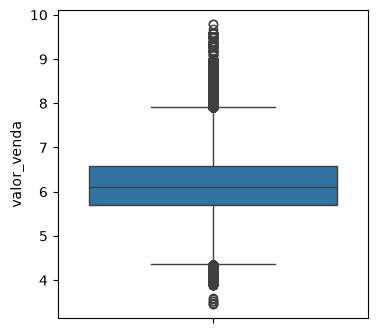

In [17]:
plotar_boxplot_geral('valor_venda', gasolina_aditivada)

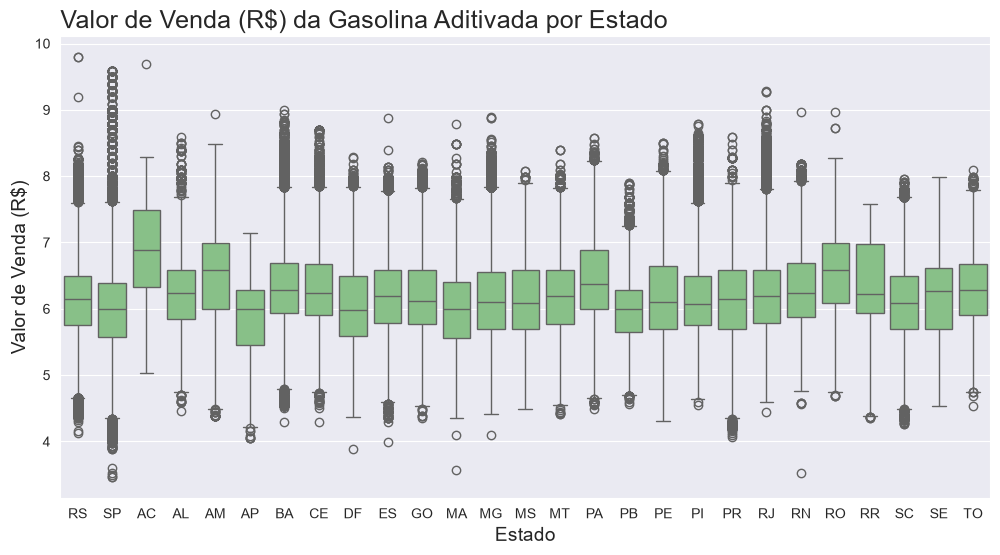

In [18]:
plotar_boxplot_2V('Valor de Venda (R$) da Gasolina Aditivada por Estado',
        'Estado',
        'Valor de Venda (R$)',
        'estado',
        'valor_venda',
        gasolina_aditivada)

In [19]:
gasolina_comum = df_anp.loc[
    df_anp['produto']
    .str.strip()
    .str.lower()
    .eq('gasolina')
].copy()

gasolina_comum['valor_venda'].describe().round(2)

count    1110764.00
mean           5.98
std            0.69
min            3.10
25%            5.50
50%            5.95
75%            6.39
max            9.29
Name: valor_venda, dtype: float64

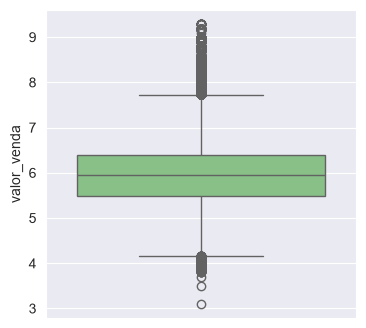

In [20]:
plotar_boxplot_geral('valor_venda', gasolina_comum)

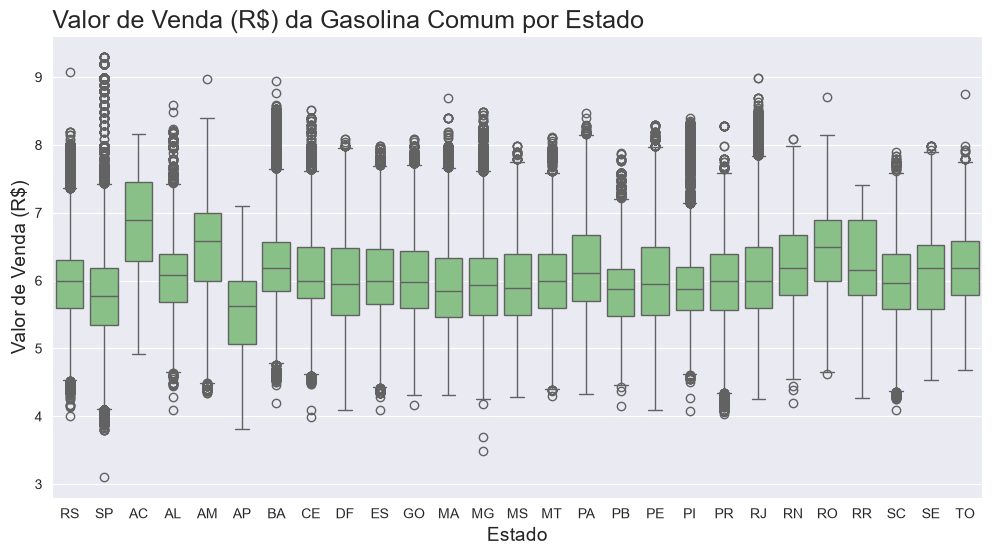

In [21]:
plotar_boxplot_2V('Valor de Venda (R$) da Gasolina Comum por Estado',
        'Estado',
        'Valor de Venda (R$)',
        'estado',
        'valor_venda',
        gasolina_comum)

In [22]:
#Estatística básica - Diesel S10
print('Diesel S10')

diesel_s10 = df_anp.loc[
    df_anp['produto']
    .str.strip()
    .str.lower()
    .eq('diesel s10')
].copy()

diesel_s10['valor_venda'].describe().round(2)

Diesel S10


count    828526.00
mean          5.93
std           0.87
min           2.80
25%           5.49
50%           5.99
75%           6.46
max           9.65
Name: valor_venda, dtype: float64

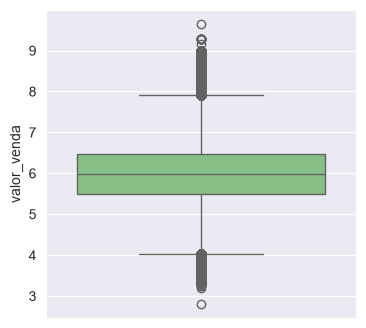

In [23]:
plotar_boxplot_geral('valor_venda', diesel_s10)

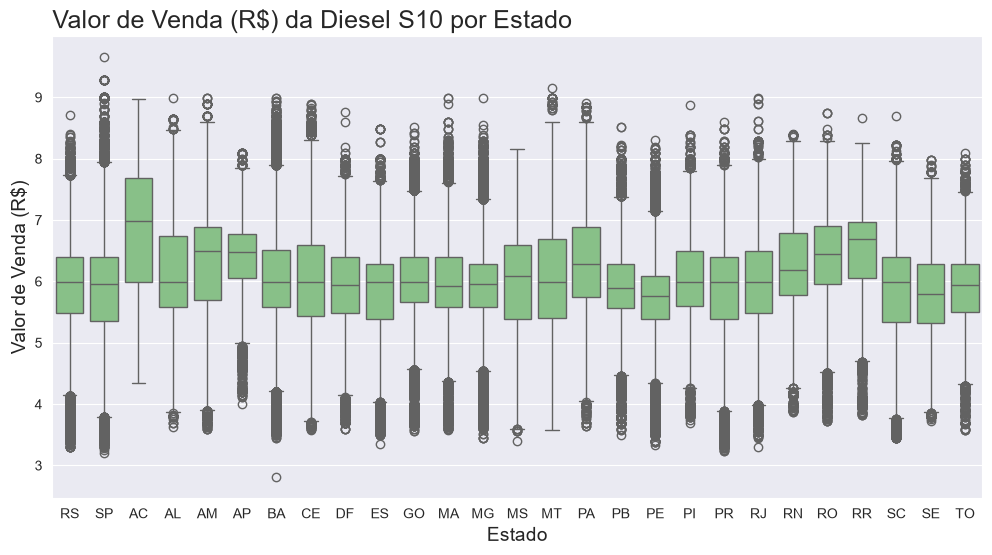

In [24]:
plotar_boxplot_2V('Valor de Venda (R$) da Diesel S10 por Estado',
        'Estado',
        'Valor de Venda (R$)',
        'estado',
        'valor_venda',
        diesel_s10)

In [25]:
#Separando o dataset
gasolina_aditivada = df_anp.loc[df_2['produto']=='GASOLINA ADITIVADA']
gasolina = df_anp.loc[df_2['produto']=='GASOLINA']
diesel_s10 = df_anp.loc[df_2['produto']=='DIESEL S10']
diesel = df_anp.loc[df_2['produto']=='DIESEL']
etanol = df_anp.loc[df_2['produto']=='ETANOL']
gnv = df_anp.loc[df_2['produto']=='GNV']

In [26]:
#Estatística básica - Diesel
print('Diesel')
diesel.valor_venda.describe().round(2)

Diesel


count    485068.00
mean          5.87
std           0.83
min           3.10
25%           5.46
50%           5.89
75%           6.36
max           9.00
Name: valor_venda, dtype: float64

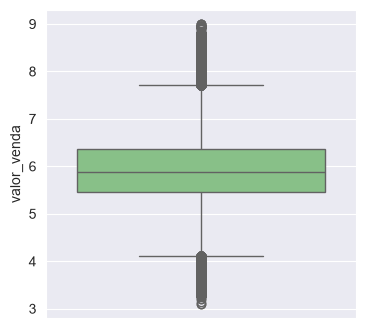

In [27]:
plotar_boxplot_geral('valor_venda', diesel)

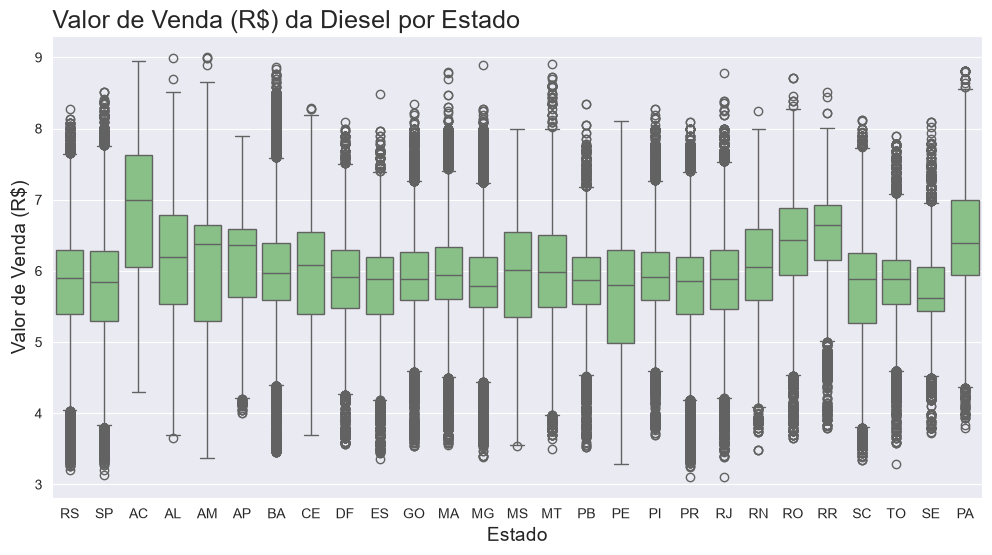

In [28]:
plotar_boxplot_2V('Valor de Venda (R$) da Diesel por Estado',
        'Estado',
        'Valor de Venda (R$)',
        'estado',
        'valor_venda',
        diesel)

In [29]:
#Estatística básica - Etanol
print('Etanol')
etanol.valor_venda.describe().round(2)

Etanol


count    957130.00
mean          4.41
std           0.73
min           2.05
25%           3.89
50%           4.30
75%           4.88
max           7.98
Name: valor_venda, dtype: float64

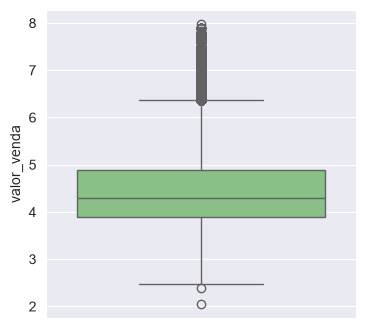

In [30]:
plotar_boxplot_geral('valor_venda', etanol)

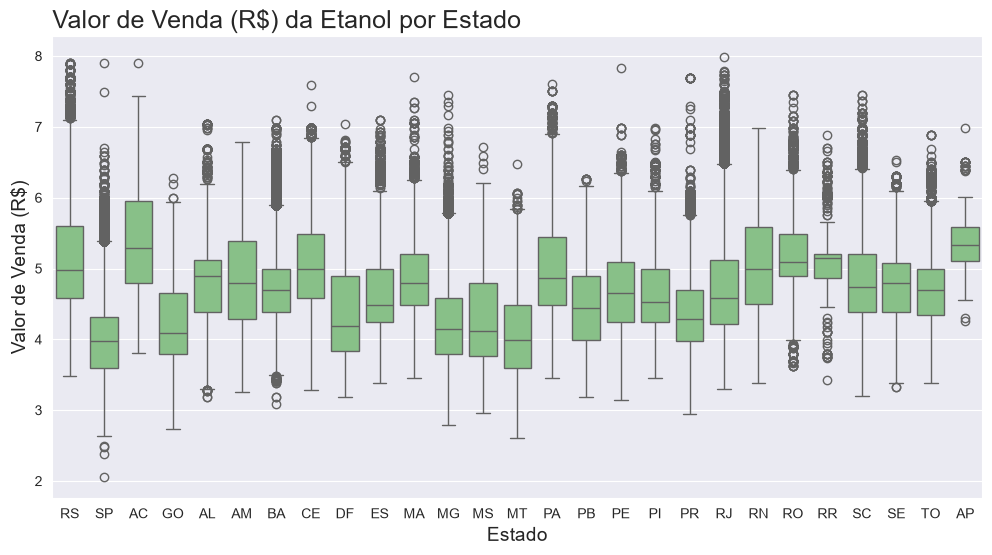

In [31]:
plotar_boxplot_2V('Valor de Venda (R$) da Etanol por Estado',
        'Estado',
        'Valor de Venda (R$)',
        'estado',
        'valor_venda',
        etanol)

In [32]:
#Estatística básica - GNV
print('GNV')
gnv.valor_venda.describe().round(2)

GNV


count    88711.00
mean         4.63
std          0.65
min          2.38
25%          4.29
50%          4.63
75%          4.99
max          7.99
Name: valor_venda, dtype: float64

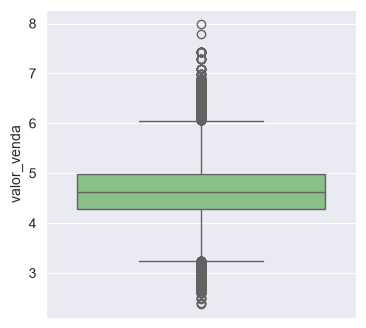

In [33]:
plotar_boxplot_geral('valor_venda', gnv)

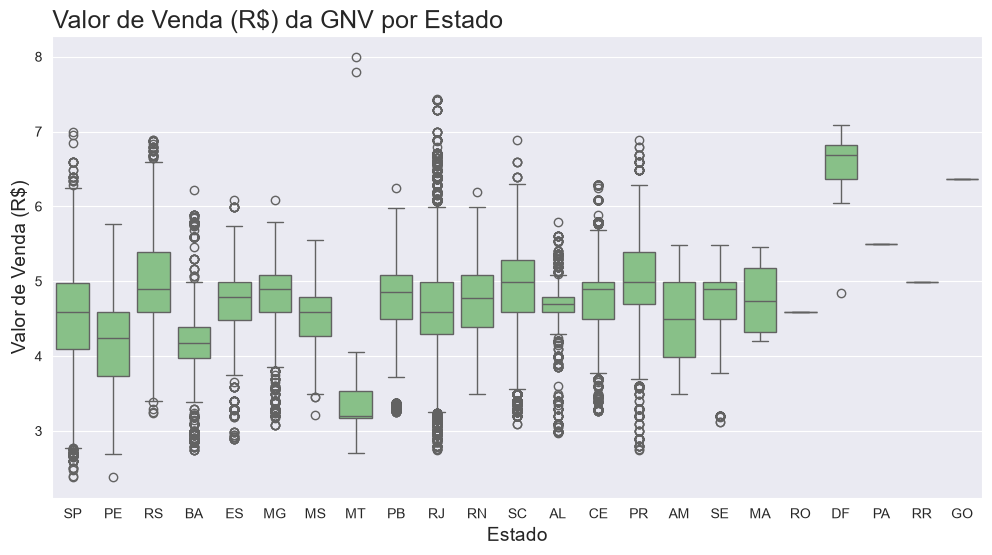

In [34]:
plotar_boxplot_2V('Valor de Venda (R$) da GNV por Estado',
        'Estado',
        'Valor de Venda (R$)',
        'estado',
        'valor_venda',
        gnv)

Primeiras linhas e colunas do dataframe df_anp

In [35]:
df_anp.head()

,data_coleta,regiao,estado,municipio,bandeira,produto,valor_venda,ano,mes
0,2021-01-01,S,RS,SAO LEOPOLDO,BRANCA,GASOLINA,4.599,2021,1
1,2021-01-01,S,RS,SAO LEOPOLDO,BRANCA,ETANOL,4.199,2021,1
2,2021-01-01,S,RS,SAO LEOPOLDO,BRANCA,GASOLINA ADITIVADA,4.799,2021,1
3,2021-01-01,S,RS,SAO LEOPOLDO,BRANCA,DIESEL,3.499,2021,1
4,2021-01-01,S,RS,SAO LEOPOLDO,BRANCA,DIESEL S10,3.599,2021,1


Qual a quantidade de bandeiras de distribuidoras de combustível no dataframe?

In [36]:
df_anp['bandeira'].nunique()

73

Quais são as bandeiras que temos no dataframe?

In [37]:
df_anp['bandeira'].unique()

<StringArray>
[                      'BRANCA',                     'IPIRANGA',
                       'RAIZEN', 'PETROBRAS DISTRIBUIDORA S.A.',
                        'SABBÁ',                       'RODOIL',
                      'ATEM' S',                        'LARCO',
                 'TOTAL BRASIL',                    'ATLÂNTICA',
                       'ALESAT',                   'RIO BRANCO',
                    'SIMARELLI',                    'ROYAL FIC',
                        'IDAZA',                      'FEDERAL',
            'TDC DISTRIBUIDORA',                       'DISLUB',
          'SETTA DISTRIBUIDORA',                          'UNI',
                       'TOBRAS',                      'CHARRUA',
                  'RAIZEN MIME',         'PETROX DISTRIBUIDORA',
                       'TEMAPE',                      'EQUADOR',
                           'SP',                        'STANG',
                     'CIAPETRO',            'RZD DISTRIBUIDORA',
           

Quais são as bandeiras que temos oor estado?

In [38]:
# Dataset com estado e bandeira
df_anp_bandeira_estado = df_anp[['estado', 'bandeira']].copy()

In [39]:
# Quantidade de bandeiras diferentes por estado
bandeiras_estado = (
    df_anp_bandeira_estado
    .dropna(subset=['bandeira'])
    .groupby('estado')['bandeira']
    .nunique()
    .reset_index(name='quantidade_bandeiras')
    .sort_values('quantidade_bandeiras', ascending=False)
    .reset_index(drop=True)
)

In [40]:
# Renomeando a coluna e mostrando o DataFrame resultante
bandeiras_estado = bandeiras_estado.rename(
    columns={'bandeira': 'quantidade_bandeiras'}
)

print(bandeiras_estado)

   estado  quantidade_bandeiras
0      SP                    24
1      PR                    23
2      GO                    20
3      SC                    20
4      PE                    17
5      MG                    17
6      RS                    17
7      PA                    16
8      RJ                    14
9      MA                    14
10     BA                    14
11     PB                    14
12     MT                    13
13     CE                    13
14     AL                    13
15     PI                    12
16     MS                    12
17     RN                    12
18     AC                    11
19     TO                    11
20     AM                    11
21     DF                    10
22     RO                    10
23     RR                     9
24     ES                     9
25     SE                     7
26     AP                     5


Gráficos das bandeiras por estado

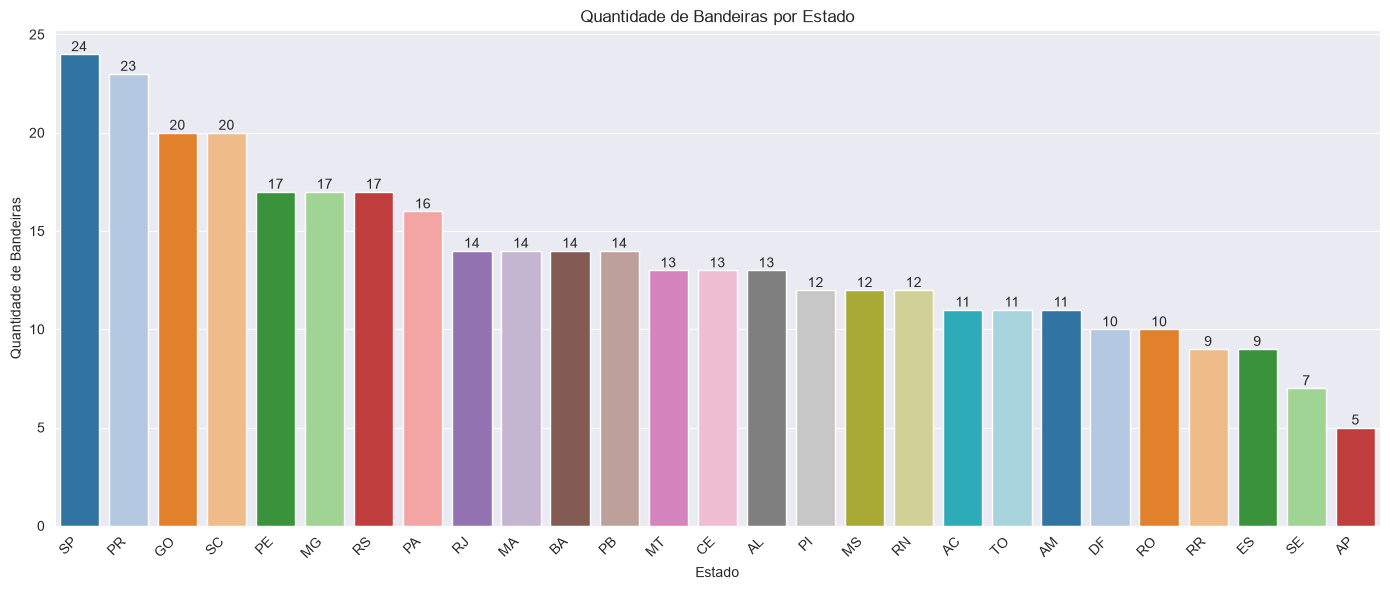

In [47]:
import os

plt.figure(figsize=(14, 6))
sns.barplot(
    x='estado', y='quantidade_bandeiras', data=bandeiras_estado,
    hue='estado', palette='tab20', legend=False
)

plt.title('Quantidade de Bandeiras por Estado')
plt.xlabel('Estado')
plt.ylabel('Quantidade de Bandeiras')
plt.xticks(rotation=45, ha='right')

for i, valor in enumerate(bandeiras_estado['quantidade_bandeiras']):
    plt.annotate(valor, xy=(i, valor), ha='center', va='bottom')

plt.tight_layout()

os.makedirs('../outputs', exist_ok=True)
plt.savefig('../outputs/quantidade_bandeiras_por_estado.png', dpi=300, bbox_inches='tight')
plt.show()